# DermaClass AI
## Dataset Research & Preparation

### Project Objective
Develop an educational skin-condition image classification
system using deep learning and computer vision.

### Initial Research Objectives
1. Identify suitable dermatology datasets.
2. Study available skin-condition categories.
3. Examine image quality and metadata.
4. Compare dataset licensing and limitations.
5. Establish a standardized classification strategy.

### Initial Candidate Datasets
- SCIN
- SkinDisNet
- Fitzpatrick17k

**Project Stage:** Phase 1 — Dataset Research

In [4]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

print("DermaClass AI environment initialized!")
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

DermaClass AI environment initialized!
Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 3.1.0


In [5]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project location:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Available folders:")

for folder in PROJECT_ROOT.iterdir():
    if folder.is_dir() and folder.name != ".venv":
        print("📁", folder.name)

Project location: C:\Users\ACER\Documents\projects\DermaClass - AI
Project exists: True
Available folders:
📁 app
📁 data
📁 docs
📁 experiments
📁 models
📁 notebooks
📁 src
📁 tests


## 1. Dataset Research

### Objective
Identify and evaluate publicly available dermatology image datasets
for the DermaClass AI classification project.

### Candidate Datasets
1. SCIN
2. SkinDisNet
3. Fitzpatrick17k

### Evaluation Criteria
- Number of images
- Available skin-condition categories
- Image quality and format
- Label reliability
- Skin-tone diversity
- Dataset licensing
- Metadata availability
- Suitability for our project

### Research Status
Pending investigation.


## 2. Dataset 1 — SCIN

### Dataset Overview
- Full Name: Skin Condition Image Network
- Developer: Google Research
- Contributions: 5,033
- Images: 10,408
- Geography: United States
- Image Source: Voluntary user submissions
- License: SCIN Data Use License

### Dataset Structure
- scin_cases.csv
- scin_labels.csv
- Image files stored separately

### Available Metadata
- Case ID
- Age group
- Sex at birth
- Fitzpatrick skin type
- Race and ethnicity
- Body parts
- Skin texture
- Symptoms
- Condition duration

### Label Information
- Dermatologist-provided condition labels
- Dermatologist confidence scores
- Weighted skin-condition labels
- Multiple possible diagnoses per case

### Advantages
1. More than 10,000 dermatology images.
2. Includes real-world user-submitted photographs.
3. Contains dermatologist annotations.
4. Includes skin-tone information.
5. Provides useful demographic and symptom metadata.

### Limitations
1. US-based contributor population.
2. Multiple possible diagnoses.
3. Missing and ambiguous labels.
4. Duplicate images.
5. Uneven representation of conditions.

### Licensing
SCIN Data Use License.
Attribution and privacy restrictions must be respected.

### Preliminary Assessment
Suitable for further investigation.

Not yet approved for model training.

### Research Status
Official source and documentation verified.

In [6]:
import pandas as pd
from pathlib import Path

# Find our project directory
candidates = [Path.cwd(), Path.cwd().parent]

PROJECT_ROOT = next(
    (p for p in candidates if (p / "data").exists()),
    Path.cwd()
)

# Create SCIN metadata folder
SCIN_DIR = PROJECT_ROOT / "data" / "raw" / "scin"
SCIN_DIR.mkdir(parents=True, exist_ok=True)

# Official SCIN metadata URLs
BASE_URL = "https://storage.googleapis.com/dx-scin-public-data/dataset"

cases_url = f"{BASE_URL}/scin_cases.csv"
labels_url = f"{BASE_URL}/scin_labels.csv"

# Download metadata
cases = pd.read_csv(cases_url)
labels = pd.read_csv(labels_url)

# Save locally
cases.to_csv(SCIN_DIR / "scin_cases.csv", index=False)
labels.to_csv(SCIN_DIR / "scin_labels.csv", index=False)

print("SCIN metadata downloaded successfully!")
print("Cases:", cases.shape)
print("Labels:", labels.shape)
print("Saved location:", SCIN_DIR)

SCIN metadata downloaded successfully!
Cases: (5033, 57)
Labels: (5033, 17)
Saved location: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin


In [7]:
# Display first 5 records from both datasets

print("========== SCIN CASES ==========")
display(cases.head())

print("========== SCIN LABELS ==========")
display(labels.head())

========== SCIN CASES ==========


,case_id,source,release,year,age_group,sex_at_birth,fitzpatrick_skin_type,race_ethnicity_american_indian_or_alaska_native,race_ethnicity_asian,race_ethnicity_black_or_african_american,...,related_category,condition_duration,image_1_path,image_2_path,image_3_path,image_1_shot_type,image_2_shot_type,image_3_shot_type,combined_race,race_ethnicity_two_or_more_after_mitigation
0,-1000600354148496558,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,...,RASH,ONE_DAY,dataset/images/-3205742176803893704.png,NaN,NaN,CLOSE_UP,NaN,NaN,NaN,NaN
1,-1002039107727665188,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,...,NaN,NaN,dataset/images/-4762289084741430925.png,NaN,NaN,CLOSE_UP,NaN,NaN,NaN,NaN
2,-1003358831658393077,SCIN,1.0.0,2023,AGE_18_TO_29,MALE,NONE_IDENTIFIED,NaN,NaN,NaN,...,OTHER_ISSUE_DESCRIPTION,ONE_TO_FOUR_WEEKS,dataset/images/-4027806997035329030.png,NaN,NaN,CLOSE_UP,NaN,NaN,HISPANIC_LATINO_OR_SPANISH_ORIGIN,NaN
3,-1003826561155964328,SCIN,1.0.0,2023,AGE_UNKNOWN,OTHER_OR_UNSPECIFIED,NaN,NaN,NaN,NaN,...,OTHER_ISSUE_DESCRIPTION,ONE_DAY,dataset/images/-5332065579713135540.png,dataset/images/-6353431708064969797.png,dataset/images/742075435141960831.png,AT_DISTANCE,AT_AN_ANGLE,CLOSE_UP,NaN,NaN
4,-1003844406100696311,SCIN,1.0.0,2023,AGE_40_TO_49,FEMALE,FST3,NaN,NaN,NaN,...,RASH,ONE_DAY,dataset/images/-3799298995660217860.png,dataset/images/-5881426422999442186.png,dataset/images/5854025080806696361.png,AT_AN_ANGLE,AT_DISTANCE,CLOSE_UP,WHITE,NaN


========== SCIN LABELS ==========


,case_id,dermatologist_gradable_for_skin_condition_1,dermatologist_gradable_for_skin_condition_2,dermatologist_gradable_for_skin_condition_3,dermatologist_skin_condition_on_label_name,dermatologist_skin_condition_confidence,weighted_skin_condition_label,dermatologist_gradable_for_fitzpatrick_skin_type_1,dermatologist_gradable_for_fitzpatrick_skin_type_2,dermatologist_gradable_for_fitzpatrick_skin_type_3,dermatologist_fitzpatrick_skin_type_label_1,dermatologist_fitzpatrick_skin_type_label_2,dermatologist_fitzpatrick_skin_type_label_3,gradable_for_monk_skin_tone_india,gradable_for_monk_skin_tone_us,monk_skin_tone_label_india,monk_skin_tone_label_us
0,-1000600354148496558,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Inflicted skin lesions', 'Eczema', 'Irritant...","[4, 4, 3]","{'Inflicted skin lesions': 0.41, 'Eczema': 0.4...",YES,NaN,NaN,FST2,NaN,NaN,True,True,2.0,1.0
1,-1002039107727665188,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Prurigo nodularis', 'Actinic Keratosis', 'SC...","[4, 3, 4]","{'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,...",YES,NaN,NaN,FST1,NaN,NaN,True,True,3.0,3.0
2,-1003358831658393077,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Impetigo', 'Herpes Zoster', 'Bullous dermati...","[2, 1, 1]","{'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul...",YES,NaN,NaN,FST4,NaN,NaN,True,True,3.0,4.0
3,-1003826561155964328,NO_IMAGE_QUALITY_INSUFFICIENT,NaN,NaN,[],[],{},NO,NaN,NaN,NaN,NaN,NaN,True,True,2.0,4.0
4,-1003844406100696311,DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT,NaN,NaN,"['Lichen planus/lichenoid eruption', 'Follicul...","[1, 1, 1]","{'Lichen planus/lichenoid eruption': 0.33, 'Fo...",YES,NaN,NaN,FST1,NaN,NaN,True,True,1.0,1.0


In [8]:
print("SCIN CASES COLUMNS:")
for column in cases.columns:
    print(column)

print("\nSCIN LABELS COLUMNS:")
for column in labels.columns:
    print(column)

SCIN CASES COLUMNS:
case_id
source
release
year
age_group
sex_at_birth
fitzpatrick_skin_type
race_ethnicity_american_indian_or_alaska_native
race_ethnicity_asian
race_ethnicity_black_or_african_american
race_ethnicity_hispanic_latino_or_spanish_origin
race_ethnicity_middle_eastern_or_north_african
race_ethnicity_native_hawaiian_or_pacific_islander
race_ethnicity_white
race_ethnicity_other_race
race_ethnicity_prefer_not_to_answer
textures_raised_or_bumpy
textures_flat
textures_rough_or_flaky
textures_fluid_filled
body_parts_head_or_neck
body_parts_arm
body_parts_palm
body_parts_back_of_hand
body_parts_torso_front
body_parts_torso_back
body_parts_genitalia_or_groin
body_parts_buttocks
body_parts_leg
body_parts_foot_top_or_side
body_parts_foot_sole
body_parts_other
condition_symptoms_bothersome_appearance
condition_symptoms_bleeding
condition_symptoms_increasing_size
condition_symptoms_darkening
condition_symptoms_itching
condition_symptoms_burning
condition_symptoms_pain
condition_sympto

In [9]:
# Inspect the skin-condition label information

print("Available label data types:")
print(labels.dtypes)

print("\nFirst 10 condition labels:")

for i, row in labels.head(10).iterrows():
    print("\nCase ID:", row["case_id"])
    print("Conditions:", row["dermatologist_skin_condition_on_label_name"])
    print("Confidence:", row["dermatologist_skin_condition_confidence"])
    print("Weighted labels:", row["weighted_skin_condition_label"])

Available label data types:
case_id                                                 int64
dermatologist_gradable_for_skin_condition_1               str
dermatologist_gradable_for_skin_condition_2               str
dermatologist_gradable_for_skin_condition_3               str
dermatologist_skin_condition_on_label_name                str
dermatologist_skin_condition_confidence                   str
weighted_skin_condition_label                             str
dermatologist_gradable_for_fitzpatrick_skin_type_1        str
dermatologist_gradable_for_fitzpatrick_skin_type_2        str
dermatologist_gradable_for_fitzpatrick_skin_type_3        str
dermatologist_fitzpatrick_skin_type_label_1               str
dermatologist_fitzpatrick_skin_type_label_2               str
dermatologist_fitzpatrick_skin_type_label_3               str
gradable_for_monk_skin_tone_india                      object
gradable_for_monk_skin_tone_us                         object
monk_skin_tone_label_india                

In [10]:
# Check whether cases are suitable for skin-condition assessment

column = "dermatologist_gradable_for_skin_condition_1"

print(labels[column].value_counts(dropna=False))

print("\nPercentage distribution:")
print(labels[column].value_counts(normalize=True, dropna=False) * 100)

dermatologist_gradable_for_skin_condition_1
DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT                     3049
NO_IMAGE_QUALITY_INSUFFICIENT                            1925
YES_IMAGE_QUALITY_SUFFICIENT_NO_DISCERNIBLE_PATHOLOGY      59
Name: count, dtype: int64

Percentage distribution:
dermatologist_gradable_for_skin_condition_1
DEFAULT_YES_IMAGE_QUALITY_SUFFICIENT                     60.580171
NO_IMAGE_QUALITY_INSUFFICIENT                            38.247566
YES_IMAGE_QUALITY_SUFFICIENT_NO_DISCERNIBLE_PATHOLOGY     1.172263
Name: proportion, dtype: float64


In [11]:
import ast
import pandas as pd

# Convert string representations of lists/dictionaries into Python objects
def parse_value(value):
    if pd.isna(value):
        return {}
    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return {}
    return value


# Extract weighted condition labels
condition_counts = {}

for value in labels["weighted_skin_condition_label"]:
    weighted_labels = parse_value(value)

    if isinstance(weighted_labels, dict):
        for condition in weighted_labels:
            condition_counts[condition] = (
                condition_counts.get(condition, 0) + 1
            )

# Convert results into a DataFrame
condition_df = pd.DataFrame(
    condition_counts.items(),
    columns=["Condition", "Case_Count"]
)

condition_df = condition_df.sort_values(
    by="Case_Count",
    ascending=False
).reset_index(drop=True)

print("Total unique conditions:", len(condition_df))
display(condition_df.head(30))

Total unique conditions: 370


,Condition,Case_Count
0,Eczema,1056
1,Allergic Contact Dermatitis,873
2,Insect Bite,403
3,Urticaria,332
4,Psoriasis,308
5,Folliculitis,268
6,Irritant Contact Dermatitis,249
7,Tinea,206
8,Drug Rash,148
9,Herpes Zoster,142


In [12]:
# Our proposed project categories
target_conditions = [
    "Acne",
    "Eczema",
    "Psoriasis",
    "Fungal infection",
    "Rosacea",
    "Contact dermatitis"
]

print("DERMACLASS AI — TARGET CONDITION CHECK\n")

for condition in target_conditions:

    matches = condition_df[
        condition_df["Condition"].str.contains(
            condition,
            case=False,
            regex=False
        )
    ]

    print(f"\n{condition}:")

    if matches.empty:
        print("No direct label match found.")
    else:
        display(matches)

DERMACLASS AI — TARGET CONDITION CHECK


Acne:


,Condition,Case_Count
16,Acne,98
174,Acne keloidalis,2
241,Acneiform eruption,1
295,Acne urticata,1



Eczema:


,Condition,Case_Count
0,Eczema,1056
54,Infected eczema,23
106,Lichenified eczematous dermatitis,6
193,Acute constitutional eczema,2
264,Acute-on-chronic dyshidrotic eczema of hands,1
302,Lichenified eczema,1
339,Crusted eczematous dermatitis,1



Psoriasis:


,Condition,Case_Count
4,Psoriasis,308
88,Parapsoriasis,8
190,Inverse psoriasis,2
205,Small plaque parapsoriasis,2


... (2 outputs left out)


Rosacea:


,Condition,Case_Count
28,Rosacea,52
326,"Rosai Dorfman disease - I know rare, but I've ...",1



Contact dermatitis:


,Condition,Case_Count
1,Allergic Contact Dermatitis,873
6,Irritant Contact Dermatitis,249
22,CD - Contact dermatitis,70
81,"Contact dermatitis, NOS",10
168,Contact dermatitis caused by Rhus diversiloba,3
223,Allergic contact dermatitis caused by allergen...,1
261,Photocontact dermatitis [berloque dermatitis],1


In [13]:
import ast
import pandas as pd

def parse_list(value):
    if isinstance(value, list):
        return value

    if isinstance(value, str):
        try:
            result = ast.literal_eval(value)
            return result if isinstance(result, list) else []
        except (ValueError, SyntaxError):
            return []

    return []

labels["parsed_conditions"] = labels[
    "dermatologist_skin_condition_on_label_name"
].apply(parse_list)

target_patterns = {
    "Acne": ["acne"],
    "Eczema": ["eczema"],
    "Psoriasis": ["psoriasis"],
    "Tinea": ["tinea"],
    "Rosacea": ["rosacea"],
    "Contact dermatitis": ["contact dermatitis"]
}

print("UNIQUE CASE COUNTS BY TARGET CONDITION\n")

for target, patterns in target_patterns.items():
    matching_cases = labels[
        labels["parsed_conditions"].apply(
            lambda conditions: any(
                pattern in condition.lower()
                for condition in conditions
                for pattern in patterns
            )
        )
    ]

    print(f"{target}: {matching_cases['case_id'].nunique()} unique cases")

UNIQUE CASE COUNTS BY TARGET CONDITION

Acne: 101 unique cases
Eczema: 1082 unique cases
Psoriasis: 317 unique cases
Tinea: 252 unique cases
Rosacea: 52 unique cases
Contact dermatitis: 1022 unique cases


In [14]:
# Identify which target conditions appear in each case

target_patterns = {
    "Acne": ["acne"],
    "Eczema": ["eczema"],
    "Psoriasis": ["psoriasis"],
    "Tinea": ["tinea"],
    "Rosacea": ["rosacea"],
    "Contact dermatitis": ["contact dermatitis"]
}

def get_target_classes(conditions):
    matched = []

    for target, patterns in target_patterns.items():
        if any(
            pattern in condition.lower()
            for condition in conditions
            for pattern in patterns
        ):
            matched.append(target)

    return matched

labels["target_classes"] = labels["parsed_conditions"].apply(
    get_target_classes
)

labels["target_class_count"] = labels["target_classes"].apply(len)

print("Cases with no target condition:",
      (labels["target_class_count"] == 0).sum())

print("Cases with exactly one target condition:",
      (labels["target_class_count"] == 1).sum())

print("Cases with multiple target conditions:",
      (labels["target_class_count"] > 1).sum())

print("\nOVERLAPPING CONDITION COMBINATIONS:")

display(
    labels[labels["target_class_count"] > 1][
        ["case_id", "target_classes"]
    ].head(20)
)

Cases with no target condition: 3091
Cases with exactly one target condition: 1201
Cases with multiple target conditions: 741

OVERLAPPING CONDITION COMBINATIONS:


,case_id,target_classes
0,-1000600354148496558,"[Eczema, Contact dermatitis]"
8,-101827005996397499,"[Eczema, Psoriasis]"
10,-1031911667791094656,"[Eczema, Contact dermatitis]"
15,-1044594585476135937,"[Psoriasis, Tinea]"
17,-1056928533969389753,"[Eczema, Contact dermatitis]"
18,-1057240568748349024,"[Psoriasis, Tinea]"
28,-1089800692688279258,"[Eczema, Psoriasis]"
33,-111683086443147412,"[Acne, Tinea, Contact dermatitis]"
51,-1175252715545111648,"[Eczema, Tinea, Contact dermatitis]"
77,-1255305323698889844,"[Tinea, Contact dermatitis]"


In [15]:
# Summarize combinations of target conditions
combination_counts = (
    labels[labels["target_class_count"] > 0]
    ["target_classes"]
    .apply(lambda x: " + ".join(sorted(x)))
    .value_counts()
    .rename_axis("Condition_Combination")
    .reset_index(name="Case_Count")
)

print("MOST COMMON TARGET CONDITION COMBINATIONS")
display(combination_counts.head(20))


# Count recorded image paths for each case
image_columns = [
    "image_1_path",
    "image_2_path",
    "image_3_path"
]

image_data = cases[["case_id"] + image_columns].copy()

image_data["recorded_image_count"] = image_data[
    image_columns
].apply(
    lambda row: sum(
        pd.notna(value) and str(value).strip() != ""
        for value in row
    ),
    axis=1
)

# Attach target labels to image information
case_image_summary = labels[
    ["case_id", "target_classes", "target_class_count"]
].merge(
    image_data[["case_id", "recorded_image_count"]],
    on="case_id",
    how="left"
)

print("\nIMAGE AVAILABILITY FOR TARGET CASES")

target_cases = case_image_summary[
    case_image_summary["target_class_count"] > 0
]

print("Target cases:", len(target_cases))
print(
    "Cases with no recorded image paths:",
    (target_cases["recorded_image_count"] == 0).sum()
)
print(
    "Cases with 1 recorded image:",
    (target_cases["recorded_image_count"] == 1).sum()
)
print(
    "Cases with 2 recorded images:",
    (target_cases["recorded_image_count"] == 2).sum()
)
print(
    "Cases with 3 recorded images:",
    (target_cases["recorded_image_count"] == 3).sum()
)

print("\nIMAGE COUNT DISTRIBUTION")
display(
    target_cases["recorded_image_count"].value_counts().sort_index()
)

MOST COMMON TARGET CONDITION COMBINATIONS


,Condition_Combination,Case_Count
0,Contact dermatitis,548
1,Eczema,431
2,Contact dermatitis + Eczema,348
3,Eczema + Psoriasis,108
4,Psoriasis,85
5,Tinea,64
6,Eczema + Tinea,61
7,Acne,57
8,Eczema + Psoriasis + Tinea,49
9,Contact dermatitis + Eczema + Tinea,38



IMAGE AVAILABILITY FOR TARGET CASES
Target cases: 1942
Cases with no recorded image paths: 0
Cases with 1 recorded image: 611
Cases with 2 recorded images: 366
Cases with 3 recorded images: 965

IMAGE COUNT DISTRIBUTION


recorded_image_count
1    611
2    366
3    965
Name: count, dtype: int64

In [16]:
# Inspect the image path structure in SCIN metadata

for column in image_columns:
    print(f"\n{column}")
    print("Non-empty paths:", cases[column].notna().sum())
    print("Examples:")
    display(cases[column].dropna().head(5))

# Check file extensions
all_paths = pd.concat(
    [cases[column] for column in image_columns],
    ignore_index=True
).dropna()

extensions = all_paths.apply(
    lambda path: Path(str(path)).suffix.lower()
)

print("\nIMAGE FILE EXTENSIONS")
display(extensions.value_counts())

# Check whether image paths are duplicated
print("\nTotal recorded paths:", len(all_paths))
print("Unique recorded paths:", all_paths.nunique())
print("Duplicate path entries:", all_paths.duplicated().sum())


image_1_path
Non-empty paths: 5033
Examples:


0    dataset/images/-3205742176803893704.png
1    dataset/images/-4762289084741430925.png
2    dataset/images/-4027806997035329030.png
3    dataset/images/-5332065579713135540.png
4    dataset/images/-3799298995660217860.png
Name: image_1_path, dtype: str


image_2_path
Non-empty paths: 3085
Examples:


3    dataset/images/-6353431708064969797.png
4    dataset/images/-5881426422999442186.png
5     dataset/images/6164754101533643044.png
6     dataset/images/-815168034213335912.png
8    dataset/images/-4055728304670056584.png
Name: image_2_path, dtype: str


image_3_path
Non-empty paths: 2289
Examples:


3      dataset/images/742075435141960831.png
4     dataset/images/5854025080806696361.png
5     dataset/images/7125798012232703466.png
6     dataset/images/8479707042238010445.png
10    dataset/images/8538075517728087299.png
Name: image_3_path, dtype: str


IMAGE FILE EXTENSIONS


.png    10407
Name: count, dtype: int64


Total recorded paths: 10407
Unique recorded paths: 10380
Duplicate path entries: 27


In [17]:
# Convert image columns into one image-path table
path_data = cases[
    ["case_id"] + image_columns
].melt(
    id_vars="case_id",
    value_vars=image_columns,
    var_name="image_column",
    value_name="image_path"
).dropna(subset=["image_path"])

# Find duplicate paths
duplicate_paths = (
    path_data.groupby("image_path")
    .agg(
        Reference_Count=("case_id", "size"),
        Unique_Cases=("case_id", "nunique"),
        Case_IDs=("case_id", list)
    )
    .query("Reference_Count > 1")
    .reset_index()
)

print("DUPLICATE IMAGE PATHS")
print("Number of duplicated paths:", len(duplicate_paths))
display(duplicate_paths.head(15))


# Check whether image files exist locally
sample_path = str(path_data.iloc[0]["image_path"])
expected_path = SCIN_DIR / sample_path

print("\nLOCAL IMAGE CHECK")
print("Example metadata path:", sample_path)
print("Expected local location:", expected_path)
print("File exists:", expected_path.exists())

existing_count = sum(
    (SCIN_DIR / str(path)).is_file()
    for path in path_data["image_path"].unique()
)

print("\nUnique image files referenced:", path_data["image_path"].nunique())
print("Files currently found locally:", existing_count)

DUPLICATE IMAGE PATHS
Number of duplicated paths: 15


,image_path,Reference_Count,Unique_Cases,Case_IDs
0,dataset/images/-25353211408586438.png,2,2,"[-2051363250643774652, -5913922383533072974]"
1,dataset/images/-25790440481901575.png,2,2,"[-2316205539922944319, -8251305011855583718]"
2,dataset/images/-6860201197263457536.png,2,2,"[-7103736510108129166, 4853076518472675176]"
3,dataset/images/-737002406762138892.png,2,2,"[-4149065585657858240, -8373370638802672214]"
4,dataset/images/-8351498747234518768.png,3,3,"[-8144595119795176997, 578470608580924545, 851..."
5,dataset/images/-8431449183703420205.png,2,2,"[-7103736510108129166, 4853076518472675176]"
6,dataset/images/-8707418133635013822.png,2,2,"[1754947382186897051, 7151606719275056352]"
7,dataset/images/-9111307368692396870.png,3,3,"[-1712619350051039848, -9099005241992076854, 2..."
8,dataset/images/1851972142048297272.png,2,2,"[1754947382186897051, 7151606719275056352]"
9,dataset/images/265617434552206306.png,3,3,"[-8144595119795176997, 578470608580924545, 851..."



LOCAL IMAGE CHECK
Example metadata path: dataset/images/-3205742176803893704.png
Expected local location: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin\dataset\images\-3205742176803893704.png
File exists: False

Unique image files referenced: 10380
Files currently found locally: 0


In [18]:
import requests
from pathlib import Path

# Select one image path from the SCIN metadata
sample_image_path = path_data.iloc[0]["image_path"]

# Construct its public Google Cloud Storage URL
image_url = (
    "https://storage.googleapis.com/"
    "dx-scin-public-data/"
    + sample_image_path
)

# Download the image into a temporary test folder
TEST_DIR = SCIN_DIR / "download_test"
TEST_DIR.mkdir(parents=True, exist_ok=True)

image_name = Path(sample_image_path).name
test_image_path = TEST_DIR / image_name

response = requests.get(image_url, timeout=60)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    test_image_path.write_bytes(response.content)

    print("Image downloaded successfully!")
    print("Saved to:", test_image_path)
    print("File size:", len(response.content), "bytes")
else:
    print("Image download failed.")
    print(response.text[:500])

HTTP Status: 200
Image downloaded successfully!
Saved to: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin\download_test\-3205742176803893704.png
File size: 999902 bytes


Image format: PNG
Image dimensions: (810, 779)
Image mode: RGB


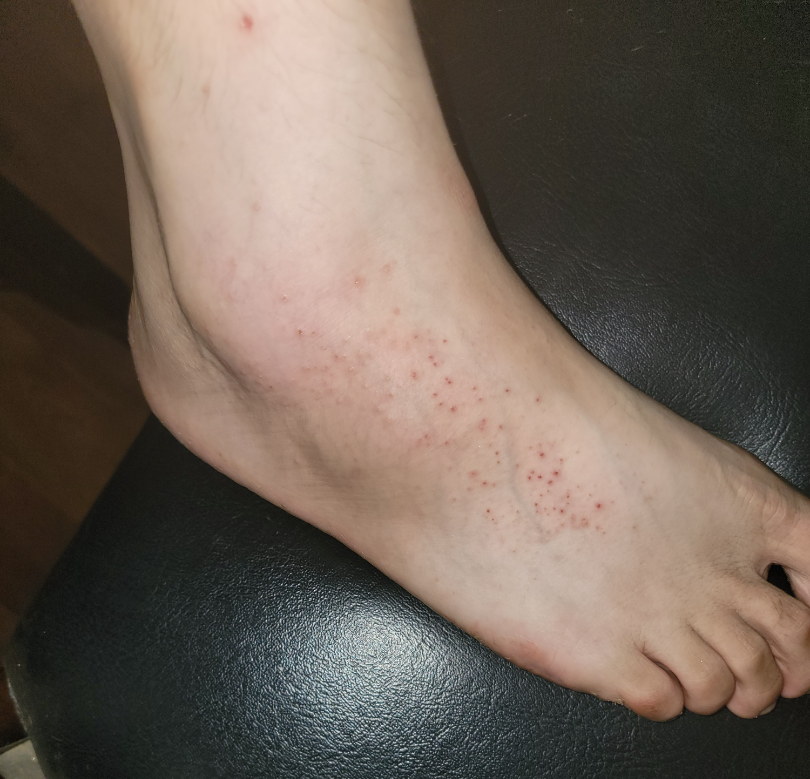

In [19]:
from PIL import Image

with Image.open(test_image_path) as img:
    print("Image format:", img.format)
    print("Image dimensions:", img.size)
    print("Image mode:", img.mode)
    display(img)

In [20]:
# Select three image paths from SCIN metadata
sample_paths = path_data["image_path"].drop_duplicates().head(3).tolist()

for path in sample_paths:
    print(path)

dataset/images/-3205742176803893704.png
dataset/images/-4762289084741430925.png
dataset/images/-4027806997035329030.png


In [21]:
# Define our four selected classes
selected_classes = [
    "Eczema",
    "Contact dermatitis",
    "Psoriasis",
    "Tinea"
]

# Keep cases containing exactly one selected 
single_label_cases = labels[
    labels["target_class_count"] == 1
].copy()

# Keep only cases whose target class is one of our four classes
single_label_cases = single_label_cases[
    single_label_cases["target_classes"].apply(
        lambda classes: len(classes) == 1
        and classes[0] in selected_classes
    )
].copy()

print("Total eligible cases:", len(single_label_cases))

print("\nCases per class:")
display(
    single_label_cases["target_classes"]
    .apply(lambda classes: classes[0])
    .value_counts()
)

Total eligible cases: 1128

Cases per class:


target_classes
Contact dermatitis    548
Eczema                431
Psoriasis              85
Tinea                  64
Name: count, dtype: int64

In [22]:
# Select image columns from the SCIN cases metadata
image_columns = [
    "image_1_path",
    "image_2_path",
    "image_3_path"
]

# Merge eligible cases with their image paths
eligible_data = single_label_cases.merge(
    cases[["case_id"] + image_columns],
    on="case_id",
    how="inner"
)

# Convert the target class list into a simple label
eligible_data["class_name"] = eligible_data[
    "target_classes"
].apply(lambda x: x[0])

print("Eligible cases:", len(eligible_data))

print("\nImage path availability:")
for column in image_columns:
    print(
        column,
        ":",
        eligible_data[column].notna().sum()
    )

display(
    eligible_data[
        ["case_id", "class_name"] + image_columns
    ].head(10)
)

Eligible cases: 1128

Image path availability:
image_1_path : 1128
image_2_path : 744
image_3_path : 539


,case_id,class_name,image_1_path,image_2_path,image_3_path
0,-1005079160214352144,Eczema,dataset/images/-3575683440831198879.png,dataset/images/6164754101533643044.png,dataset/images/7125798012232703466.png
1,-1060130963443704102,Contact dermatitis,dataset/images/-7488721783507435350.png,dataset/images/5053055464292650713.png,NaN
2,-1079717215777778516,Eczema,dataset/images/-3060870142909393201.png,NaN,NaN
3,-1087381795155772077,Psoriasis,dataset/images/-1306941150253534667.png,NaN,NaN
4,-1101392520794914783,Psoriasis,dataset/images/-8195825849611846307.png,dataset/images/-8250386929233656434.png,dataset/images/9096596305603840450.png
5,-1120481478267460560,Eczema,dataset/images/-3933475004882152757.png,dataset/images/-6233451743223829948.png,dataset/images/-764324206369620251.png
6,-113091225230567987,Eczema,dataset/images/-1979417173631887595.png,dataset/images/2869390005959410844.png,dataset/images/6251975297204365136.png
7,-1131745754224368828,Eczema,dataset/images/4174575629707577584.png,NaN,NaN
8,-1137468110374856758,Eczema,dataset/images/-420948865655293968.png,dataset/images/-8926558499250236160.png,dataset/images/6561837420168089247.png
9,-1147365175896762601,Eczema,dataset/images/-3194582777873313186.png,dataset/images/-78242243559460767.png,dataset/images/3201833674357467711.png


In [23]:
# Convert the three image columns into one image list

image_manifest = eligible_data[
    ["case_id", "class_name"] + image_columns
].melt(
    id_vars=["case_id", "class_name"],
    value_vars=image_columns,
    var_name="image_column",
    value_name="image_path"
)

# Remove empty image paths
image_manifest = image_manifest.dropna(
    subset=["image_path"]
).copy()

# Remove accidental whitespace
image_manifest["image_path"] = (
    image_manifest["image_path"].str.strip()
)

# Count unique image paths
print("Total image references:", len(image_manifest))
print(
    "Unique image paths:",
    image_manifest["image_path"].nunique()
)

# Identify paths associated with multiple cases
duplicate_summary = (
    image_manifest.groupby("image_path")
    .agg(
        reference_count=("case_id", "size"),
        unique_cases=("case_id", "nunique"),
        unique_classes=("class_name", "nunique"),
        classes=("class_name", lambda x: list(set(x)))
    )
    .reset_index()
)

duplicates = duplicate_summary[
    duplicate_summary["reference_count"] > 1
]

print("\nDuplicated image paths:", len(duplicates))

print("\nDuplicates associated with different classes:")
display(
    duplicates[
        duplicates["unique_classes"] > 1
    ]
)

Total image references: 2411
Unique image paths: 2406

Duplicated image paths: 5

Duplicates associated with different classes:


,image_path,reference_count,unique_cases,unique_classes,classes


In [24]:
# Create a clean manifest with one row per unique image

clean_manifest = (
    image_manifest
    .drop_duplicates(subset=["image_path"])
    [["case_id", "class_name", "image_path"]]
    .reset_index(drop=True)
)

print("Total unique images:", len(clean_manifest))

print("\nImages per class:")
display(
    clean_manifest["class_name"].value_counts()
)

print("\nClean manifest preview:")
display(clean_manifest.head(10))

Total unique images: 2406

Images per class:


class_name
Contact dermatitis    1171
Eczema                 931
Psoriasis              182
Tinea                  122
Name: count, dtype: int64


Clean manifest preview:


,case_id,class_name,image_path
0,-1005079160214352144,Eczema,dataset/images/-3575683440831198879.png
1,-1060130963443704102,Contact dermatitis,dataset/images/-7488721783507435350.png
2,-1079717215777778516,Eczema,dataset/images/-3060870142909393201.png
3,-1087381795155772077,Psoriasis,dataset/images/-1306941150253534667.png
4,-1101392520794914783,Psoriasis,dataset/images/-8195825849611846307.png
5,-1120481478267460560,Eczema,dataset/images/-3933475004882152757.png
6,-113091225230567987,Eczema,dataset/images/-1979417173631887595.png
7,-1131745754224368828,Eczema,dataset/images/4174575629707577584.png
8,-1137468110374856758,Eczema,dataset/images/-420948865655293968.png
9,-1147365175896762601,Eczema,dataset/images/-3194582777873313186.png


In [25]:
# Create a manifest folder
MANIFEST_DIR = SCIN_DIR / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

# Save the clean image manifest
manifest_path = MANIFEST_DIR / "scin_four_class_manifest.csv"

clean_manifest.to_csv(manifest_path, index=False)

print("Manifest saved successfully!")
print("Location:", manifest_path)
print("Total images:", len(clean_manifest))

Manifest saved successfully!
Location: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin\manifests\scin_four_class_manifest.csv
Total images: 2406


In [26]:
import pandas as pd
from pathlib import Path

# Load our saved image manifest
manifest_path = SCIN_DIR / "manifests" / "scin_four_class_manifest.csv"

download_manifest = pd.read_csv(manifest_path)

# Create the destination folder
IMAGE_DIR = SCIN_DIR / "selected_images"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Display basic information
print("Manifest loaded successfully!")
print("Images to download:", len(download_manifest))
print("Download folder:", IMAGE_DIR)
print("Folder exists:", IMAGE_DIR.exists())

Manifest loaded successfully!
Images to download: 2406
Download folder: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin\selected_images
Folder exists: True


In [27]:
# Create a CSV file to track download results
DOWNLOAD_LOG = SCIN_DIR / "download_log.csv"

# Check whether a previous download log exists
if DOWNLOAD_LOG.exists():
    download_log = pd.read_csv(DOWNLOAD_LOG)
    print("Existing download log loaded.")
else:
    download_log = pd.DataFrame(
        columns=["image_path", "status", "error"]
    )
    download_log.to_csv(DOWNLOAD_LOG, index=False)
    print("New download log created.")

print("Download log location:", DOWNLOAD_LOG)
display(download_log.head())

Existing download log loaded.
Download log location: C:\Users\ACER\Documents\projects\DermaClass - AI\data\raw\scin\download_log.csv


,image_path,status,error
0,dataset/images/-3575683440831198879.png,success,NaN
1,dataset/images/-7488721783507435350.png,success,NaN
2,dataset/images/-3060870142909393201.png,success,NaN
3,dataset/images/-1306941150253534667.png,success,NaN
4,dataset/images/-8195825849611846307.png,success,NaN


In [28]:
# Get image paths already marked as successfully downloaded
completed_images = set(
    download_log.loc[
        download_log["status"] == "success",
        "image_path"
    ]
)

# Identify images that still need downloading
pending_images = download_manifest[
    ~download_manifest["image_path"].isin(completed_images)
].copy()

print("Total images:", len(download_manifest))
print("Already downloaded:", len(completed_images))
print("Pending downloads:", len(pending_images))

Total images: 2406
Already downloaded: 2185
Pending downloads: 221


In [29]:
import requests
import time
from PIL import Image
from io import BytesIO

# Download counters
successful = 0
failed = 0

for index, row in pending_images.iterrows():

    image_path = row["image_path"]
    image_name = Path(image_path).name
    save_path = IMAGE_DIR / image_name

    try:
        # Construct image URL
        image_url = (
            "https://storage.googleapis.com/"
            "dx-scin-public-data/"
            + image_path
        )

        # Download image
        response = requests.get(image_url, timeout=60)
        response.raise_for_status()

        # Verify that the response contains a valid image
        with Image.open(BytesIO(response.content)) as img:
            img.verify()

        # Save image
        save_path.write_bytes(response.content)

        status = "success"
        error_message = ""
        successful += 1

    except Exception as error:
        status = "failed"
        error_message = str(error)
        failed += 1

    # Record the result
    new_record = pd.DataFrame([{
        "image_path": image_path,
        "status": status,
        "error": error_message
    }])

    download_log = pd.concat(
        [download_log, new_record],
        ignore_index=True
    )

    # Save progress after every 25 images
    if (successful + failed) % 25 == 0:
        download_log.to_csv(DOWNLOAD_LOG, index=False)
        print(
            f"Processed: {successful + failed}/{len(pending_images)}"
            f" | Successful: {successful}"
            f" | Failed: {failed}"
        )

    time.sleep(0.1)

# Save final download log
download_log.to_csv(DOWNLOAD_LOG, index=False)

print("\nDOWNLOAD SUMMARY")
print("Successful:", successful)
print("Failed:", failed)
print("Log saved:", DOWNLOAD_LOG)

Processed: 25/221 | Successful: 24 | Failed: 1



KeyboardInterrupt


KeyboardInterrupt



In [ ]:
# Count successful and failed downloads
print("DOWNLOAD STATUS SUMMARY")

display(
    download_log["status"].value_counts()
)

# Inspect the most common error messages
print("\nMOST COMMON ERRORS")

display(
    download_log.loc[
        download_log["status"] == "failed",
        "error"
    ].value_counts().head(15)
)

# Show five failed download examples
print("\nSAMPLE FAILED DOWNLOADS")

display(
    download_log.loc[
        download_log["status"] == "failed",
        ["image_path", "error"]
    ].head(5)
)

In [ ]:
# Check total and unique records in the download log

print("TOTAL LOG RECORDS:", len(download_log))

print(
    "UNIQUE IMAGE PATHS:",
    download_log["image_path"].nunique()
)

print("\nSTATUS COUNTS:")
display(download_log["status"].value_counts())

# Find image paths appearing more than once
log_duplicates = download_log[
    download_log["image_path"].duplicated(keep=False)
]

print(
    "\nDUPLICATE LOG RECORDS:",
    len(log_duplicates)
)

# Check the latest status recorded for each image
latest_log = download_log.drop_duplicates(
    subset=["image_path"],
    keep="last"
)

print("\nLATEST STATUS PER UNIQUE IMAGE:")
display(latest_log["status"].value_counts())

# Check how many images are physically present
existing_files = sum(
    (IMAGE_DIR / Path(path).name).is_file()
    for path in download_manifest["image_path"]
)

print("\nFILES PRESENT LOCALLY:", existing_files)

In [ ]:
# Check total and unique records in the download log

print("TOTAL LOG RECORDS:", len(download_log))

print(
    "UNIQUE IMAGE PATHS:",
    download_log["image_path"].nunique()
)

print("\nSTATUS COUNTS:")
display(download_log["status"].value_counts())

# Find image paths appearing more than once
log_duplicates = download_log[
    download_log["image_path"].duplicated(keep=False)
]

print(
    "\nDUPLICATE LOG RECORDS:",
    len(log_duplicates)
)

# Check the latest status recorded for each image
latest_log = download_log.drop_duplicates(
    subset=["image_path"],
    keep="last"
)

print("\nLATEST STATUS PER UNIQUE IMAGE:")
display(latest_log["status"].value_counts())

# Check how many images are physically present
existing_files = sum(
    (IMAGE_DIR / Path(path).name).is_file()
    for path in download_manifest["image_path"]
)

print("\nFILES PRESENT LOCALLY:", existing_files)

In [ ]:
from PIL import Image
from pathlib import Path

valid_images = []
invalid_images = []
missing_images = []

for image_path in download_manifest["image_path"]:

    image_name = Path(image_path).name
    local_path = IMAGE_DIR / image_name

    if not local_path.exists():
        missing_images.append(image_path)
        continue

    try:
        with Image.open(local_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception:
        invalid_images.append(image_path)

print("IMAGE AUDIT RESULTS")
print("-------------------")
print("Total manifest images:", len(download_manifest))
print("Valid downloaded images:", len(valid_images))
print("Missing images:", len(missing_images))
print("Corrupted images:", len(invalid_images))

In [ ]:
# Identify missing image paths
missing_manifest = download_manifest[
    download_manifest["image_path"].isin(missing_images)
].copy()

print("MISSING IMAGES BY CLASS")

display(
    missing_manifest["class_name"].value_counts()
)

print("\nTOTAL MISSING:", len(missing_manifest))

In [ ]:
# Create a separate recovery log
RECOVERY_LOG = SCIN_DIR / "recovery_log.csv"

recovery_log = pd.DataFrame(
    columns=["image_path", "status", "error", "attempts"]
)

recovery_log.to_csv(RECOVERY_LOG, index=False)

print("Recovery log created!")
print("Location:", RECOVERY_LOG)
print("Images to recover:", len(missing_manifest))

In [ ]:
import requests
import time
import pandas as pd
from pathlib import Path
from PIL import Image
from io import BytesIO

# Download counters
recovered = 0
failed = 0

# Maximum retry attempts
MAX_RETRIES = 4

# Start recovery
for index, row in missing_manifest.iterrows():

    image_path = row["image_path"]
    image_name = Path(image_path).name
    save_path = IMAGE_DIR / image_name

    # Skip if a valid image already exists
    if save_path.exists():
        try:
            with Image.open(save_path) as img:
                img.verify()

            recovered += 1
            continue

        except Exception:
            pass

    image_url = (
        "https://storage.googleapis.com/"
        "dx-scin-public-data/"
        + image_path
    )

    status = "failed"
    error_message = ""

    for attempt in range(1, MAX_RETRIES + 1):

        try:
            response = requests.get(
                image_url,
                timeout=60
            )

            response.raise_for_status()

            # Verify downloaded image
            with Image.open(BytesIO(response.content)) as img:
                img.verify()

            # Save valid image
            save_path.write_bytes(response.content)

            status = "success"
            error_message = ""
            recovered += 1
            break

        except requests.exceptions.HTTPError as error:

            error_code = error.response.status_code

            error_message = str(error)

            # Permanent missing-file error
            if error_code == 404:
                break

            # Retry temporary server errors and rate limits
            if error_code not in [429, 500, 502, 503, 504]:
                break

        except Exception as error:
            error_message = str(error)

        if attempt < MAX_RETRIES:
            wait_time = 2 ** attempt
            time.sleep(wait_time)

    if status == "failed":
        failed += 1

    # Save one result for this image
    new_record = pd.DataFrame([{
        "image_path": image_path,
        "status": status,
        "error": error_message,
        "attempts": attempt
    }])

    recovery_log = pd.concat(
        [recovery_log, new_record],
        ignore_index=True
    )

    # Save recovery progress after every image
    recovery_log.to_csv(
        RECOVERY_LOG,
        index=False
    )

    # Display progress
    if (index + 1) % 25 == 0:
        print(
            f"Processed: {index + 1}/{len(missing_manifest)}"
            f" | Recovered: {recovered}"
            f" | Failed: {failed}"
        )

    time.sleep(0.2)

print("\nRECOVERY SUMMARY")
print("Recovered:", recovered)
print("Failed:", failed)
print("Recovery log:", RECOVERY_LOG)

In [ ]:
from PIL import Image
from pathlib import Path

valid_images = []
missing_images = []
invalid_images = []

for image_path in download_manifest["image_path"]:

    image_name = Path(image_path).name
    local_path = IMAGE_DIR / image_name

    if not local_path.is_file():
        missing_images.append(image_path)
        continue

    try:
        with Image.open(local_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception:
        invalid_images.append(image_path)

print("FINAL IMAGE AUDIT")
print("------------------")
print("Expected images:", len(download_manifest))
print("Valid images:", len(valid_images))
print("Missing images:", len(missing_images))
print("Invalid images:", len(invalid_images))

In [ ]:
failed_recovery = recovery_log[
    recovery_log["status"] == "failed"
]

print("Failed recovery records:", len(failed_recovery))

display(
    failed_recovery[
        ["image_path", "error", "attempts"]
    ]
)

In [ ]:
import requests
import time
from io import BytesIO
from PIL import Image
from pathlib import Path

retry_rows = failed_recovery[
    ~failed_recovery["error"].str.contains("404", na=False)
]

recovered_now = 0
still_failed = 0

for _, row in retry_rows.iterrows():
    image_path = row["image_path"]
    image_name = Path(image_path).name
    save_path = IMAGE_DIR / image_name
    image_url = (
        "https://storage.googleapis.com/dx-scin-public-data/"
        + image_path
    )

    success = False
    last_error = None

    for attempt in range(1, 4):
        try:
            response = requests.get(image_url, timeout=60)
            response.raise_for_status()

            image = Image.open(BytesIO(response.content))
            image.verify()

            save_path.write_bytes(response.content)
            success = True
            recovered_now += 1

            recovery_log.loc[len(recovery_log)] = {
                "image_path": image_path,
                "status": "success",
                "error": "",
                "attempts": attempt
            }
            break

        except Exception as error:
            last_error = str(error)
            time.sleep(2 ** attempt)

    if not success:
        still_failed += 1
        recovery_log.loc[len(recovery_log)] = {
            "image_path": image_path,
            "status": "failed",
            "error": last_error,
            "attempts": 3
        }

    recovery_log.to_csv(RECOVERY_LOG, index=False)

print("Additional images recovered:", recovered_now)
print("Still failing:", still_failed)

In [ ]:
from PIL import Image
from pathlib import Path

valid_images = []
missing_images = []
invalid_images = []

for image_path in download_manifest["image_path"]:

    image_name = Path(image_path).name
    local_path = IMAGE_DIR / image_name

    if not local_path.is_file():
        missing_images.append(image_path)
        continue

    try:
        with Image.open(local_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception:
        invalid_images.append(image_path)

print("FINAL IMAGE AUDIT")
print("------------------")
print("Expected images:", len(download_manifest))
print("Valid images:", len(valid_images))
print("Missing images:", len(missing_images))
print("Invalid images:", len(invalid_images))

In [ ]:
# Get the filenames of all valid images
valid_image_names = {
    Path(image_path).name
    for image_path in download_manifest["image_path"]
    if (IMAGE_DIR / Path(image_path).name).is_file()
    and Path(image_path).name not in {
        Path(p).name for p in missing_images
    }
}

# Keep all original case-image relationships for valid images
verified_manifest = image_manifest[
    image_manifest["image_path"].apply(
        lambda p: Path(p).name in valid_image_names
    )
].copy()

# Save the verified manifest
VERIFIED_MANIFEST = (
    SCIN_DIR / "manifests" / "scin_four_class_verified_manifest.csv"
)

verified_manifest.to_csv(VERIFIED_MANIFEST, index=False)

print("Verified image relationships:", len(verified_manifest))
print("Unique verified images:", verified_manifest["image_path"].nunique())
print("Saved to:", VERIFIED_MANIFEST)

In [ ]:
duplicate_relations = verified_manifest[
    verified_manifest.duplicated(
        subset=["image_path"],
        keep=False
    )
].sort_values("image_path")

print("Rows involved in duplicate paths:", len(duplicate_relations))
print("Number of duplicated paths:",
      duplicate_relations["image_path"].nunique())

display(duplicate_relations)

In [ ]:
from collections import defaultdict

# Build a graph: cases connected by shared image paths
image_to_cases = (
    verified_manifest.groupby("image_path")["case_id"]
    .apply(lambda x: list(set(x)))
)

case_graph = defaultdict(set)

for case_list in image_to_cases:
    if len(case_list) > 1:
        for case_id in case_list:
            case_graph[case_id].update(
                other for other in case_list if other != case_id
            )

# Find connected components
visited = set()
case_groups = []

for case_id in verified_manifest["case_id"].unique():
    if case_id in visited:
        continue

    stack = [case_id]
    group = set()

    while stack:
        current = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        group.add(current)
        stack.extend(case_graph[current] - visited)

    case_groups.append(group)

print("Total case groups:", len(case_groups))
print("Groups containing multiple cases:",
      sum(len(group) > 1 for group in case_groups))

for group in case_groups:
    if len(group) > 1:
        print("Connected cases:", sorted(group))

In [ ]:
case_to_group = {}

for group_number, group in enumerate(case_groups):
    for case_id in group:
        case_to_group[case_id] = group_number

verified_manifest["group_id"] = (
    verified_manifest["case_id"].map(case_to_group)
)

print("Unique groups:", verified_manifest["group_id"].nunique())
print("Missing group IDs:", verified_manifest["group_id"].isna().sum())

display(
    verified_manifest[
        ["case_id", "class_name", "group_id"]
    ].drop_duplicates().head(10)
)

In [ ]:
group_distribution = (
    verified_manifest[
        ["group_id", "class_name"]
    ]
    .drop_duplicates()
    ["class_name"]
    .value_counts()
)

print("Case groups per class:")
display(group_distribution)

print("\nTotal groups:", group_distribution.sum())

In [ ]:
group_table = (
    verified_manifest[
        ["group_id", "class_name"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Rows:", len(group_table))
print("Unique groups:", group_table["group_id"].nunique())
print("\nClass distribution:")
display(group_table["class_name"].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_groups, temp_groups = train_test_split(
    group_table,
    test_size=0.30,
    stratify=group_table["class_name"],
    random_state=42
)

# Second split: 15% validation, 15% testing
val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    stratify=temp_groups["class_name"],
    random_state=42
)

print("Training groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Testing groups:", len(test_groups))

In [ ]:
split_distribution = pd.DataFrame({
    "Training": train_groups["class_name"].value_counts(),
    "Validation": val_groups["class_name"].value_counts(),
    "Testing": test_groups["class_name"].value_counts()
}).fillna(0).astype(int)

print("Class distribution across splits:")
display(split_distribution)

print("\nPercentage distribution:")
display(
    split_distribution.div(
        split_distribution.sum(axis=0), axis=1
    ).mul(100).round(2)
)

In [ ]:
# Create a mapping from group ID to split name
group_to_split = {}

for group_id in train_groups["group_id"]:
    group_to_split[group_id] = "train"

for group_id in val_groups["group_id"]:
    group_to_split[group_id] = "validation"

for group_id in test_groups["group_id"]:
    group_to_split[group_id] = "test"

# Assign each image relationship to its group's split
verified_manifest["split"] = (
    verified_manifest["group_id"].map(group_to_split)
)

print("Split assignment counts:")
display(verified_manifest["split"].value_counts())

print("\nMissing split assignments:",
      verified_manifest["split"].isna().sum())

In [ ]:
# Check whether any group appears in multiple splits
group_split_counts = (
    verified_manifest.groupby("group_id")["split"].nunique()
)

# Check whether any image appears in multiple splits
image_split_counts = (
    verified_manifest.groupby("image_path")["split"].nunique()
)

print("Groups appearing in multiple splits:",
      (group_split_counts > 1).sum())

print("Images appearing in multiple splits:",
      (image_split_counts > 1).sum())

In [ ]:
# Create the split-manifest directory
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Save each split separately
train_manifest = verified_manifest[
    verified_manifest["split"] == "train"
].copy()

val_manifest = verified_manifest[
    verified_manifest["split"] == "validation"
].copy()

test_manifest = verified_manifest[
    verified_manifest["split"] == "test"
].copy()

train_manifest.to_csv(
    SPLIT_DIR / "train_manifest.csv", index=False
)

val_manifest.to_csv(
    SPLIT_DIR / "validation_manifest.csv", index=False
)

test_manifest.to_csv(
    SPLIT_DIR / "test_manifest.csv", index=False
)

print("Saved split manifests:")
print("Training:", len(train_manifest))
print("Validation:", len(val_manifest))
print("Testing:", len(test_manifest))
print("Directory:", SPLIT_DIR)

In [ ]:
print("LABEL DATASET SHAPE:", labels.shape)

print("\nLABEL DATASET COLUMNS:")
for column in labels.columns:
    print("-", column)

In [ ]:
print("DERMATOLOGIST CONFIDENCE VALUES:")
print(
    labels["dermatologist_skin_condition_confidence"]
    .value_counts(dropna=False)
)

print("\nDATA TYPE:")
print(labels["dermatologist_skin_condition_confidence"].dtype)

In [30]:
import ast

# Convert string representations into actual Python lists
labels["confidence_list"] = labels[
    "dermatologist_skin_condition_confidence"
].apply(ast.literal_eval)

# Count how many confidence values each case has
labels["confidence_count"] = labels[
    "confidence_list"
].apply(len)

print("NUMBER OF CONFIDENCE VALUES PER CASE:")
display(labels["confidence_count"].value_counts().sort_index())

print("\nINDIVIDUAL CONFIDENCE SCORES:")
all_scores = [
    score
    for scores in labels["confidence_list"]
    for score in scores
]

print(pd.Series(all_scores).value_counts().sort_index())

NUMBER OF CONFIDENCE VALUES PER CASE:


confidence_count
0    1972
1     670
2     774
3    1162
4     126
5     116
6     113
7      62
8      29
9       9
Name: count, dtype: int64


INDIVIDUAL CONFIDENCE SCORES:
1    2278
2    2639
3    1131
4    1287
5     878
Name: count, dtype: int64


In [31]:
# Convert dermatologist condition labels into Python lists
labels["dermatologist_labels_list"] = labels[
    "dermatologist_skin_condition_on_label_name"
].apply(ast.literal_eval)

# Compare the number of labels and confidence scores per case
labels["label_count"] = labels[
    "dermatologist_labels_list"
].apply(len)

labels["confidence_count"] = labels[
    "confidence_list"
].apply(len)

# Identify cases where the list lengths do not match
mismatches = labels[
    labels["label_count"] != labels["confidence_count"]
]

print("Total cases:", len(labels))
print("Cases with matching lengths:",
      (labels["label_count"] == labels["confidence_count"]).sum())
print("Cases with mismatched lengths:", len(mismatches))

display(
    mismatches[
        [
            "case_id",
            "dermatologist_labels_list",
            "confidence_list"
        ]
    ].head(10)
)

Total cases: 5033
Cases with matching lengths: 5033
Cases with mismatched lengths: 0


,case_id,dermatologist_labels_list,confidence_list


In [32]:
# Display five cases with their paired labels and confidence scores
sample_cases = labels[
    labels["confidence_count"] > 0
].head(5)

for _, row in sample_cases.iterrows():
    print("\nCase ID:", row["case_id"])

    for condition, confidence in zip(
        row["dermatologist_labels_list"],
        row["confidence_list"]
    ):
        print(f"  Condition: {condition} | Confidence: {confidence}")


Case ID: -1000600354148496558
  Condition: Inflicted skin lesions | Confidence: 4
  Condition: Eczema | Confidence: 4
  Condition: Irritant Contact Dermatitis | Confidence: 3

Case ID: -1002039107727665188
  Condition: Prurigo nodularis | Confidence: 4
  Condition: Actinic Keratosis | Confidence: 3
  Condition: SCC/SCCIS | Confidence: 4

Case ID: -1003358831658393077
  Condition: Impetigo | Confidence: 2
  Condition: Herpes Zoster | Confidence: 1
  Condition: Bullous dermatitis | Confidence: 1

Case ID: -1003844406100696311
  Condition: Lichen planus/lichenoid eruption | Confidence: 1
  Condition: Folliculitis | Confidence: 1
  Condition: Dermatosis due to flea | Confidence: 1

Case ID: -1005079160214352144
  Condition: Drug Rash | Confidence: 2
  Condition: Viral Exanthem | Confidence: 2
  Condition: Eczema | Confidence: 1


In [33]:
target_confidence_records = []

for _, row in labels.iterrows():
    for condition, confidence in zip(
        row["dermatologist_labels_list"],
        row["confidence_list"]
    ):
        if condition in [
            "Allergic Contact Dermatitis",
            "Irritant Contact Dermatitis",
            "Contact Dermatitis",
            "Eczema",
            "Psoriasis",
            "Tinea"
        ]:
            target_confidence_records.append({
                "case_id": row["case_id"],
                "condition": condition,
                "confidence": confidence
            })

target_confidence_df = pd.DataFrame(target_confidence_records)

print("Target condition confidence records:",
      len(target_confidence_df))

display(
    pd.crosstab(
        target_confidence_df["condition"],
        target_confidence_df["confidence"]
    )
)

Target condition confidence records: 2997


confidence,1,2,3,4,5
condition,,,,,
Allergic Contact Dermatitis,298,351,130,128,45
Eczema,377,308,166,213,147
Irritant Contact Dermatitis,20,155,29,45,5
Psoriasis,136,111,39,36,26
Tinea,88,54,34,30,26


In [34]:
print("WEIGHTED LABEL DISTRIBUTION:")

display(
    labels["weighted_skin_condition_label"]
    .value_counts()
    .head(25)
)

print("\nEXAMPLE WEIGHTED LABELS:")

display(
    labels[
        [
            "case_id",
            "dermatologist_labels_list",
            "confidence_list",
            "weighted_skin_condition_label"
        ]
    ].head(10)
)

WEIGHTED LABEL DISTRIBUTION:


weighted_skin_condition_label
{}                                                                            1972
{'Eczema': 1.0}                                                                127
{'Urticaria': 1.0}                                                              85
{'Allergic Contact Dermatitis': 1.0}                                            42
{'Folliculitis': 1.0}                                                           38
{'Insect Bite': 1.0}                                                            28
{'Allergic Contact Dermatitis': 0.5, 'Irritant Contact Dermatitis': 0.5}        27
{'Acute dermatitis, NOS': 1.0}                                                  27
{'Eczema': 0.5, 'Allergic Contact Dermatitis': 0.5}                             27
{'Allergic Contact Dermatitis': 0.67, 'Irritant Contact Dermatitis': 0.33}      21
{'Allergic Contact Dermatitis': 0.67, 'Eczema': 0.33}                           21
{'O/E - ecchymoses present': 1.0}                        


EXAMPLE WEIGHTED LABELS:


,case_id,dermatologist_labels_list,confidence_list,weighted_skin_condition_label
0,-1000600354148496558,"[Inflicted skin lesions, Eczema, Irritant Cont...","[4, 4, 3]","{'Inflicted skin lesions': 0.41, 'Eczema': 0.4..."
1,-1002039107727665188,"[Prurigo nodularis, Actinic Keratosis, SCC/SCCIS]","[4, 3, 4]","{'Prurigo nodularis': 0.41, 'SCC/SCCIS': 0.41,..."
2,-1003358831658393077,"[Impetigo, Herpes Zoster, Bullous dermatitis]","[2, 1, 1]","{'Impetigo': 0.55, 'Herpes Zoster': 0.23, 'Bul..."
3,-1003826561155964328,[],[],{}
4,-1003844406100696311,"[Lichen planus/lichenoid eruption, Folliculiti...","[1, 1, 1]","{'Lichen planus/lichenoid eruption': 0.33, 'Fo..."
5,-1005079160214352144,"[Drug Rash, Viral Exanthem, Eczema]","[2, 2, 1]","{'Drug Rash': 0.41, 'Viral Exanthem': 0.41, 'E..."
6,-1010778459521153386,"[Urticaria, Leukocytoclastic Vasculitis, Urtic...","[4, 2, 5, 1, 1]","{'Urticaria': 0.6, 'Leukocytoclastic Vasculiti..."
7,-1013831220015814987,"[Inflicted skin lesions, Basal Cell Carcinoma,...","[2, 4, 1]","{'Basal Cell Carcinoma': 0.55, 'Inflicted skin..."
8,-101827005996397499,"[Psoriasis, Eczema, Eczema, Acute and chronic ...","[1, 3, 3, 2, 4, 3]","{'Eczema': 0.67, 'Psoriasis': 0.11, 'Acute and..."
9,-1022162013984621110,[Purpura],[3],{'Purpura': 1.0}


In [35]:
# Convert weighted labels from strings into dictionaries
labels["weighted_label_dict"] = labels[
    "weighted_skin_condition_label"
].apply(ast.literal_eval)

# Count the number of labels in each dictionary
labels["weighted_label_count"] = labels[
    "weighted_label_dict"
].apply(len)

print("NUMBER OF LABELS PER WEIGHTED DISTRIBUTION:")

display(
    labels["weighted_label_count"]
    .value_counts()
    .sort_index()
)

print("\nCASES WITH ONE DOMINANT LABEL:")
print((labels["weighted_label_count"] == 1).sum())

print("\nCASES WITH MULTIPLE LABELS:")
print((labels["weighted_label_count"] > 1).sum())

print("\nCASES WITH NO WEIGHTED LABEL:")
print((labels["weighted_label_count"] == 0).sum())

NUMBER OF LABELS PER WEIGHTED DISTRIBUTION:


weighted_label_count
0    1972
1     690
2     805
3    1241
4     161
5     116
6      37
7       8
8       3
Name: count, dtype: int64


CASES WITH ONE DOMINANT LABEL:
690

CASES WITH MULTIPLE LABELS:
2371

CASES WITH NO WEIGHTED LABEL:
1972


In [36]:
# Extract the highest weight from each weighted-label dictionary
labels["dominant_weight"] = labels[
    "weighted_label_dict"
].apply(
    lambda d: max(d.values()) if d else None
)

print("DOMINANT WEIGHT DISTRIBUTION:")

display(
    labels["dominant_weight"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nDOMINANT WEIGHT SUMMARY:")
display(labels["dominant_weight"].describe())

DOMINANT WEIGHT DISTRIBUTION:


dominant_weight
0.16       1
0.17       2
0.18       1
0.19       1
0.20       1
        ... 
0.78       8
0.80       4
0.86       7
1.00     690
NaN     1972
Name: count, Length: 61, dtype: int64


DOMINANT WEIGHT SUMMARY:


count    3061.00000
mean        0.61572
std         0.23666
min         0.16000
25%         0.41000
50%         0.55000
75%         0.67000
max         1.00000
Name: dominant_weight, dtype: float64

In [39]:
quality_data = eligible_data[
    ["case_id", "class_name"]
].drop_duplicates(
    subset=["case_id"]
).merge(
    labels[
        ["case_id", "weighted_label_dict", "dominant_weight"]
    ],
    on="case_id",
    how="left"
)

print("DOMINANT WEIGHT BY CLASS:")

display(
    quality_data.groupby("class_name")["dominant_weight"]
    .describe()
)

quality_data["high_dominance"] = (
    quality_data["dominant_weight"] >= 0.80
)

print("\nCASES WITH DOMINANT WEIGHT >= 0.80:")

display(
    quality_data.groupby("class_name")["high_dominance"]
    .agg(["sum", "count"])
)

DOMINANT WEIGHT BY CLASS:


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Contact dermatitis,548.0,0.559106,0.199010,0.22,0.4100,0.55,0.67,1.0
Eczema,431.0,0.666868,0.244917,0.25,0.5000,0.67,1.00,1.0
Psoriasis,85.0,0.608471,0.240429,0.22,0.4100,0.55,0.69,1.0
Tinea,64.0,0.704531,0.247514,0.33,0.5375,0.67,1.00,1.0



CASES WITH DOMINANT WEIGHT >= 0.80:


,sum,count
class_name,,
Contact dermatitis,66,548
Eczema,132,431
Psoriasis,18,85
Tinea,24,64


In [40]:
def get_class_weight(row):
    class_name = row["class_name"]
    weighted_labels = row["weighted_label_dict"]

    if class_name == "Contact dermatitis":
        return sum(
            weighted_labels.get(label, 0)
            for label in [
                "Allergic Contact Dermatitis",
                "Irritant Contact Dermatitis",
                "Contact Dermatitis"
            ]
        )

    if class_name == "Eczema":
        return weighted_labels.get("Eczema", 0)

    if class_name == "Psoriasis":
        return weighted_labels.get("Psoriasis", 0)

    if class_name == "Tinea":
        return weighted_labels.get("Tinea", 0)

quality_data["class_label_weight"] = quality_data.apply(
    get_class_weight, axis=1
)

print("CLASS LABEL WEIGHT DISTRIBUTION:")

display(
    quality_data.groupby("class_name")["class_label_weight"]
    .describe()
)

print("\nCASES WITH ZERO WEIGHT FOR THEIR ASSIGNED CLASS:")

display(
    quality_data.groupby("class_name")["class_label_weight"]
    .apply(lambda x: (x == 0).sum())
)

CLASS LABEL WEIGHT DISTRIBUTION:


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Contact dermatitis,548.0,0.484252,0.311351,0.0,0.23,0.39,0.67,1.0
Eczema,431.0,0.551810,0.329290,0.0,0.33,0.50,1.00,1.0
Psoriasis,85.0,0.462235,0.319077,0.0,0.23,0.33,0.67,1.0
Tinea,64.0,0.347969,0.380243,0.0,0.00,0.28,0.55,1.0



CASES WITH ZERO WEIGHT FOR THEIR ASSIGNED CLASS:


class_name
Contact dermatitis    27
Eczema                15
Psoriasis              6
Tinea                 27
Name: class_label_weight, dtype: int64

In [41]:
def get_class_weight(row):
    class_name = row["class_name"]
    weighted_labels = row["weighted_label_dict"]

    if class_name == "Contact dermatitis":
        return sum(
            weighted_labels.get(label, 0)
            for label in [
                "Allergic Contact Dermatitis",
                "Irritant Contact Dermatitis",
                "Contact Dermatitis"
            ]
        )

    if class_name == "Eczema":
        return weighted_labels.get("Eczema", 0)

    if class_name == "Psoriasis":
        return weighted_labels.get("Psoriasis", 0)

    if class_name == "Tinea":
        return weighted_labels.get("Tinea", 0)

quality_data["class_label_weight"] = quality_data.apply(
    get_class_weight, axis=1
)

print("CLASS LABEL WEIGHT DISTRIBUTION:")

display(
    quality_data.groupby("class_name")["class_label_weight"]
    .describe()
)

print("\nCASES WITH ZERO WEIGHT FOR THEIR ASSIGNED CLASS:")

display(
    quality_data.groupby("class_name")["class_label_weight"]
    .apply(lambda x: (x == 0).sum())
)

CLASS LABEL WEIGHT DISTRIBUTION:


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Contact dermatitis,548.0,0.484252,0.311351,0.0,0.23,0.39,0.67,1.0
Eczema,431.0,0.551810,0.329290,0.0,0.33,0.50,1.00,1.0
Psoriasis,85.0,0.462235,0.319077,0.0,0.23,0.33,0.67,1.0
Tinea,64.0,0.347969,0.380243,0.0,0.00,0.28,0.55,1.0



CASES WITH ZERO WEIGHT FOR THEIR ASSIGNED CLASS:


class_name
Contact dermatitis    27
Eczema                15
Psoriasis              6
Tinea                 27
Name: class_label_weight, dtype: int64

In [42]:
# Collect every unique condition name from weighted dictionaries
all_weighted_names = set()

for weighted_dict in labels["weighted_label_dict"]:
    all_weighted_names.update(weighted_dict.keys())

# Find relevant condition-name variants
keywords = [
    "tinea",
    "fung",
    "dermatitis",
    "eczema",
    "psoriasis"
]

matching_names = sorted([
    name for name in all_weighted_names
    if any(keyword in name.lower() for keyword in keywords)
])

print("RELEVANT WEIGHTED-LABEL VARIANTS:")

for name in matching_names:
    print("-", name)

print("\nTotal matching names:", len(matching_names))

RELEVANT WEIGHTED-LABEL VARIANTS:
- Acute and chronic dermatitis
- Acute constitutional eczema
- Acute dermatitis
- Acute dermatitis, NOS
- Acute vesicular dermatitis
- Acute-on-chronic dyshidrotic eczema of hands
- Allergic Contact Dermatitis
- Allergic contact dermatitis caused by allergenic hapten derived from plant
- Berloque dermatitis
- Bullous dermatitis
- Bullous dermatitis, NOS
- CD - Contact dermatitis
- Chronic dermatitis
- Chronic dermatitis, NOS
- Contact dermatitis caused by Rhus diversiloba
- Contact dermatitis, NOS
- Crusted eczematous dermatitis
- Deep fungal infection
- Dermatitis herpetiformis
- Eczema
- Fungal dermatitis
- Fungal dermatosis
- Infected eczema
- Inverse psoriasis
- Irritant Contact Dermatitis
- Lichenified eczema
- Lichenified eczematous dermatitis
- Papular acrodermatitis of childhood
- Parapsoriasis
- Perioral Dermatitis
- Photocontact dermatitis [berloque dermatitis]
- Photodermatitis
- Phytophotodermatitis
- Pruritic dermatitis
- Psoriasiform derm

In [43]:
variant_frequency = {}

for weighted_dict in labels["weighted_label_dict"]:
    for condition, weight in weighted_dict.items():
        if any(
            keyword in condition.lower()
            for keyword in [
                "tinea", "fung", "dermatitis",
                "eczema", "psoriasis"
            ]
        ):
            variant_frequency[condition] = (
                variant_frequency.get(condition, 0) + 1
            )

variant_frequency_df = pd.DataFrame(
    list(variant_frequency.items()),
    columns=["condition", "case_frequency"]
).sort_values(
    "case_frequency",
    ascending=False
)

display(variant_frequency_df)

,condition,case_frequency
0,Eczema,1056
5,Allergic Contact Dermatitis,873
3,Psoriasis,308
1,Irritant Contact Dermatitis,249
11,Tinea,206
13,"Acute dermatitis, NOS",124
7,Stasis Dermatitis,70
17,CD - Contact dermatitis,70
6,Tinea Versicolor,53
4,Acute and chronic dermatitis,47


In [44]:
selected_weighted_names = set()

for weighted_dict in quality_data["weighted_label_dict"]:
    selected_weighted_names.update(weighted_dict.keys())

selected_weighted_names = sorted(selected_weighted_names)

print("WEIGHTED LABELS IN SELECTED CASES:")

for name in selected_weighted_names:
    print("-", name)

print("\nTotal unique labels:", len(selected_weighted_names))

WEIGHTED LABELS IN SELECTED CASES:
- AKV - Acrokeratosis verruciformis
- Abrasion and/or friction burn of lower limb without infection
- Abrasion and/or friction burn of thigh without infection
- Abrasion of wrist
- Abrasion, scrape, or scab
- Abscess
- Acanthosis nigricans
- Acral erythema
- Actinic Keratosis
- Actinic granuloma
- Acute and chronic dermatitis
- Acute constitutional eczema
- Acute dermatitis, NOS
- Acute generalised exanthematous pustulosis
- Acute vesicular dermatitis
- Acute-on-chronic dyshidrotic eczema of hands
- Adnexal neoplasm
- Allergic Contact Dermatitis
- Allergic contact dermatitis caused by allergenic hapten derived from plant
- Amyloidosis of skin
- Animal bite - wound
- Annular erythema
- Basal Cell Carcinoma
- Berloque dermatitis
- Bullosis diabeticorum
- Bullous Pemphigoid
- Bullous dermatosis
- Burn of skin
- CD - Contact dermatitis
- Candida
- Candida intertrigo
- Candidal intertrigo
- Cat scratch disease
- Cellulitis
- Cellulitis of hand excluding fi

In [45]:
class_label_mapping = {
    "Contact dermatitis": [
        "Allergic Contact Dermatitis",
        "Irritant Contact Dermatitis",
        "CD - Contact dermatitis",
        "Contact dermatitis, NOS",
        "Berloque dermatitis",
        "Contact dermatitis caused by Rhus diversiloba"
    ],

    "Eczema": [
        "Eczema",
        "Infected eczema",
        "Lichenified eczema",
        "Lichenified eczematous dermatitis",
        "Acute constitutional eczema",
        "Acute-on-chronic dyshidrotic eczema of hands"
    ],

    "Psoriasis": [
        "Psoriasis",
        "Inverse psoriasis"
    ],

    "Tinea": [
        "Tinea",
        "Tinea Versicolor",
        "Deep fungal infection",
        "Fungal dermatitis",
        "Fungal dermatosis"
    ]
}


def calculate_mapped_weight(row):
    weighted_dict = row["weighted_label_dict"]

    return sum(
        weighted_dict.get(label, 0)
        for label in class_label_mapping[row["class_name"]]
    )


quality_data["mapped_class_weight"] = quality_data.apply(
    calculate_mapped_weight,
    axis=1
)

print("MAPPED CLASS WEIGHT DISTRIBUTION:")

display(
    quality_data.groupby("class_name")["mapped_class_weight"]
    .describe()
)

print("\nCASES WITH ZERO MAPPED WEIGHT:")

display(
    quality_data.groupby("class_name")["mapped_class_weight"]
    .apply(lambda x: (x == 0).sum())
)

MAPPED CLASS WEIGHT DISTRIBUTION:


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Contact dermatitis,548.0,0.524854,0.301592,0.10,0.27,0.495,0.7425,1.0
Eczema,431.0,0.569930,0.317616,0.08,0.33,0.500,1.0000,1.0
Psoriasis,85.0,0.472588,0.311311,0.00,0.27,0.330,0.6700,1.0
Tinea,64.0,0.653438,0.307784,0.10,0.39,0.550,1.0000,1.0



CASES WITH ZERO MAPPED WEIGHT:


class_name
Contact dermatitis    0
Eczema                0
Psoriasis             4
Tinea                 0
Name: mapped_class_weight, dtype: int64

In [46]:
psoriasis_zero_cases = quality_data[
    (quality_data["class_name"] == "Psoriasis") &
    (quality_data["mapped_class_weight"] == 0)
]

display(
    psoriasis_zero_cases[
        [
            "case_id",
            "weighted_label_dict",
            "mapped_class_weight"
        ]
    ].to_string(index=False)
)

"             case_id                                                                       weighted_label_dict  mapped_class_weight\n-6020814934897747901          {'Pityriasis rosea': 0.71, 'Syphilis': 0.15, 'Small plaque parapsoriasis': 0.15}                  0.0\n-6688622400916552994          {'Pityriasis rosea': 0.55, 'Small plaque parapsoriasis': 0.27, 'Syphilis': 0.18}                  0.0\n 1812780772789288074                  {'Parapsoriasis': 0.33, 'Syphilis': 0.33, 'Seborrheic Dermatitis': 0.33}                  0.0\n 1818532041670121872 {'Cutaneous T Cell Lymphoma': 0.55, 'Parapsoriasis': 0.27, 'deep fungal infection': 0.18}                  0.0"

In [48]:
psoriasis_case_ids = psoriasis_zero_cases["case_id"].tolist()

display(
    labels[
        labels["case_id"].isin(psoriasis_case_ids)
    ][
        [
            "case_id",
            "dermatologist_labels_list",
            "confidence_list",
            "weighted_label_dict"
        ]
    ].to_string(index=False)
)

"             case_id                                                  dermatologist_labels_list confidence_list                                                                       weighted_label_dict\n-6020814934897747901 [Pityriasis rosea, Pityriasis rosea, Syphilis, Small plaque parapsoriasis]    [4, 5, 1, 1]          {'Pityriasis rosea': 0.71, 'Syphilis': 0.15, 'Small plaque parapsoriasis': 0.15}\n-6688622400916552994                   [Pityriasis rosea, Syphilis, Small plaque parapsoriasis]       [4, 1, 2]          {'Pityriasis rosea': 0.55, 'Small plaque parapsoriasis': 0.27, 'Syphilis': 0.18}\n 1812780772789288074                           [Parapsoriasis, Syphilis, Seborrheic Dermatitis]       [2, 2, 2]                  {'Parapsoriasis': 0.33, 'Syphilis': 0.33, 'Seborrheic Dermatitis': 0.33}\n 1818532041670121872          [Parapsoriasis, deep fungal infection, Cutaneous T Cell Lymphoma]       [3, 2, 4] {'Cutaneous T Cell Lymphoma': 0.55, 'Parapsoriasis': 0.27, 'deep fungal inf

In [49]:
# Identify all cases with zero mapped class weight
zero_weight_cases = quality_data[
    quality_data["mapped_class_weight"] == 0
].copy()

print("TOTAL ZERO-WEIGHT CASES:",
      len(zero_weight_cases))

print("\nZERO-WEIGHT CASES BY CLASS:")
display(
    zero_weight_cases["class_name"].value_counts()
)

print("\nALL FLAGGED CASES:")
display(
    zero_weight_cases[
        [
            "case_id",
            "class_name",
            "weighted_label_dict",
            "mapped_class_weight"
        ]
    ].to_string(index=False)
)

TOTAL ZERO-WEIGHT CASES: 4

ZERO-WEIGHT CASES BY CLASS:


class_name
Psoriasis    4
Name: count, dtype: int64


ALL FLAGGED CASES:


"             case_id class_name                                                                       weighted_label_dict  mapped_class_weight\n-6020814934897747901  Psoriasis          {'Pityriasis rosea': 0.71, 'Syphilis': 0.15, 'Small plaque parapsoriasis': 0.15}                  0.0\n-6688622400916552994  Psoriasis          {'Pityriasis rosea': 0.55, 'Small plaque parapsoriasis': 0.27, 'Syphilis': 0.18}                  0.0\n 1812780772789288074  Psoriasis                  {'Parapsoriasis': 0.33, 'Syphilis': 0.33, 'Seborrheic Dermatitis': 0.33}                  0.0\n 1818532041670121872  Psoriasis {'Cutaneous T Cell Lymphoma': 0.55, 'Parapsoriasis': 0.27, 'deep fungal infection': 0.18}                  0.0"

In [50]:
# Store the case IDs identified as label disagreements
label_disagreement_ids = set(
    zero_weight_cases["case_id"]
)

# Add an exclusion flag to the quality dataset
quality_data["label_disagreement"] = (
    quality_data["case_id"].isin(label_disagreement_ids)
)

quality_data["include_in_strict_training"] = (
    ~quality_data["label_disagreement"]
)

print("LABEL QUALITY AUDIT SUMMARY")

display(
    quality_data.groupby("class_name").agg(
        original_cases=("case_id", "count"),
        flagged_cases=("label_disagreement", "sum"),
        eligible_cases=("include_in_strict_training", "sum")
    )
)

LABEL QUALITY AUDIT SUMMARY


,original_cases,flagged_cases,eligible_cases
class_name,,,
Contact dermatitis,548,0,548
Eczema,431,0,431
Psoriasis,85,4,81
Tinea,64,0,64


In [54]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"

print("Project directory:", PROJECT_ROOT)
print("Split directory:", SPLIT_DIR)
print("Directory exists:", SPLIT_DIR.exists())

Project directory: C:\Users\ACER\Documents\projects\DermaClass - AI
Split directory: C:\Users\ACER\Documents\projects\DermaClass - AI\data\splits
Directory exists: True


In [55]:
train_manifest = pd.read_csv(
    SPLIT_DIR / "train_manifest.csv"
)

val_manifest = pd.read_csv(
    SPLIT_DIR / "validation_manifest.csv"
)

test_manifest = pd.read_csv(
    SPLIT_DIR / "test_manifest.csv"
)

verified_manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True
)

print("Reloaded rows:", len(verified_manifest))
print("Unique images:", verified_manifest["image_path"].nunique())
print("Unique groups:", verified_manifest["group_id"].nunique())

Reloaded rows: 2410
Unique images: 2405
Unique groups: 1126


In [56]:
print("ROWS PER SAVED SPLIT:")
print("Training:", len(train_manifest))
print("Validation:", len(val_manifest))
print("Testing:", len(test_manifest))

print("\nDUPLICATE IMAGE PATHS:")
duplicates = verified_manifest[
    verified_manifest.duplicated(
        subset=["image_path"],
        keep=False
    )
].sort_values("image_path")

display(duplicates)

print("\nROWS PER SPLIT:")
display(verified_manifest["split"].value_counts())

ROWS PER SAVED SPLIT:
Training: 1694
Validation: 369
Testing: 347

DUPLICATE IMAGE PATHS:


,case_id,class_name,image_column,image_path,group_id,split
137,-4149065585657858240,Contact dermatitis,image_1_path,dataset/images/-737002406762138892.png,200,train
350,-8373370638802672214,Contact dermatitis,image_1_path,dataset/images/-737002406762138892.png,200,train
422,1754947382186897051,Contact dermatitis,image_1_path,dataset/images/-8707418133635013822.png,607,train
678,7151606719275056352,Contact dermatitis,image_1_path,dataset/images/-8707418133635013822.png,607,train
1073,1754947382186897051,Contact dermatitis,image_2_path,dataset/images/1851972142048297272.png,607,train
1242,7151606719275056352,Contact dermatitis,image_2_path,dataset/images/1851972142048297272.png,607,train
880,-4149065585657858240,Contact dermatitis,image_2_path,dataset/images/4013268428021902865.png,200,train
1027,-8373370638802672214,Contact dermatitis,image_2_path,dataset/images/4013268428021902865.png,200,train
1383,-4149065585657858240,Contact dermatitis,image_3_path,dataset/images/9068834759287693167.png,200,train
1482,-8373370638802672214,Contact dermatitis,image_3_path,dataset/images/9068834759287693167.png,200,train



ROWS PER SPLIT:


split
train         1694
validation     369
test           347
Name: count, dtype: int64

In [57]:
# Restore the original manifest location
SCIN_DIR = PROJECT_ROOT / "data" / "raw" / "scin"

original_manifest = pd.read_csv(
    SCIN_DIR / "manifests" / "scin_four_class_verified_manifest.csv"
)

# Compare case-image relationships
original_pairs = set(
    zip(original_manifest["case_id"], original_manifest["image_path"])
)

reloaded_pairs = set(
    zip(verified_manifest["case_id"], verified_manifest["image_path"])
)

extra_pairs = reloaded_pairs - original_pairs
missing_pairs = original_pairs - reloaded_pairs

print("Original relationships:", len(original_pairs))
print("Reloaded relationships:", len(reloaded_pairs))
print("Extra relationships:", len(extra_pairs))
print("Missing relationships:", len(missing_pairs))

print("\nEXTRA ROWS:")
display(
    verified_manifest[
        verified_manifest.apply(
            lambda row: (row["case_id"], row["image_path"]) in extra_pairs,
            axis=1
        )
    ]
)

Original relationships: 2410
Reloaded relationships: 2410
Extra relationships: 0
Missing relationships: 0

EXTRA ROWS:


,case_id,class_name,image_column,image_path,group_id,split


In [58]:
flagged_split_info = verified_manifest[
    verified_manifest["case_id"].isin(label_disagreement_ids)
][
    ["case_id", "class_name", "group_id", "split"]
].drop_duplicates()

print("FLAGGED CASES BY SPLIT:")
display(flagged_split_info.sort_values("split"))

print("\nAffected groups:",
      flagged_split_info["group_id"].nunique())

FLAGGED CASES BY SPLIT:


,case_id,class_name,group_id,split
2111,-6688622400916552994,Psoriasis,381,test
2155,1812780772789288074,Psoriasis,609,test
240,-6020814934897747901,Psoriasis,333,train
1788,1818532041670121872,Psoriasis,611,validation



Affected groups: 4


In [59]:
# Remove only the four flagged cases
corrected_manifest = verified_manifest[
    ~verified_manifest["case_id"].isin(label_disagreement_ids)
].copy()

# Recreate the three corrected splits
corrected_train = corrected_manifest[
    corrected_manifest["split"] == "train"
].copy()

corrected_val = corrected_manifest[
    corrected_manifest["split"] == "validation"
].copy()

corrected_test = corrected_manifest[
    corrected_manifest["split"] == "test"
].copy()

print("CORRECTED MANIFEST COUNTS")
print("Training:", len(corrected_train))
print("Validation:", len(corrected_val))
print("Testing:", len(corrected_test))
print("Total:", len(corrected_manifest))

print("\nRemaining unique cases:",
      corrected_manifest["case_id"].nunique())

CORRECTED MANIFEST COUNTS
Training: 1691
Validation: 368
Testing: 342
Total: 2401

Remaining unique cases: 1124


In [60]:
print("FLAGGED CASES REMAINING:",
      corrected_manifest["case_id"].isin(
          label_disagreement_ids
      ).sum())

print("GROUPS IN MULTIPLE SPLITS:",
      (corrected_manifest.groupby("group_id")["split"]
       .nunique() > 1).sum())

print("IMAGES IN MULTIPLE SPLITS:",
      (corrected_manifest.groupby("image_path")["split"]
       .nunique() > 1).sum())

print("UNIQUE IMAGE FILES:",
      corrected_manifest["image_path"].nunique())

print("UNIQUE CASES:",
      corrected_manifest["case_id"].nunique())

FLAGGED CASES REMAINING: 0
GROUPS IN MULTIPLE SPLITS: 0
IMAGES IN MULTIPLE SPLITS: 0
UNIQUE IMAGE FILES: 2396
UNIQUE CASES: 1124


In [61]:
# Save corrected manifests separately
corrected_train.to_csv(
    SPLIT_DIR / "train_manifest_v2.csv",
    index=False
)

corrected_val.to_csv(
    SPLIT_DIR / "validation_manifest_v2.csv",
    index=False
)

corrected_test.to_csv(
    SPLIT_DIR / "test_manifest_v2.csv",
    index=False
)

corrected_manifest.to_csv(
    SPLIT_DIR / "full_verified_manifest_v2.csv",
    index=False
)

print("CORRECTED MANIFESTS SAVED")

print("Training:", len(corrected_train))
print("Validation:", len(corrected_val))
print("Testing:", len(corrected_test))
print("Total:", len(corrected_manifest))
print("Location:", SPLIT_DIR)

CORRECTED MANIFESTS SAVED
Training: 1691
Validation: 368
Testing: 342
Total: 2401
Location: C:\Users\ACER\Documents\projects\DermaClass - AI\data\splits
